In [1]:
import numpy as np
import networkx as nx
from scipy.sparse import csr_matrix
import scipy.linalg as la
import matplotlib.pyplot as plt

In [2]:
class basisStates:
    def __init__(self, L):
        self.L = L
        self.dim = 2**L

    def state(self, index):
        return format(index, f"0{self.L}b")

    def getIndex(self, state):
        return int(state, 2)
    
    def getAllBasisStates(self):
        return [self.state(i) for i in range(self.dim)]
    
    def x(self, index, site):
        if index is None:
            return None

        operated_state = self.state(index)

        flipped_bit = str(1 - int(operated_state[site]))

        new_state = operated_state[:site] + flipped_bit + operated_state[site+1:]
        
        return self.getIndex(new_state)
    
    def p(self, index, site):
        if index is None:
            return None

        operated_state = self.state(index)
    
        if operated_state[site] == '1':
            return None
        else:
            return index

    def pxp(self, index, site):

        new_index = self.p(index, (site - 1) % self.L)

        if new_index is None:
            return None

        new_index = self.p(new_index, (site + 1) % self.L)

        if new_index is None:
            return None

        new_index = self.x(new_index, site)

        return new_index

    def translate(self, index, shift = 1):
        if index is None:
            return None

        state = self.state(index)
        translated_state = state[-shift:] + state[:-shift]
        return self.getIndex(translated_state)


### Task 1

- Generate sparse matrix representation of the Hamiltonian H
- Analyze the structure of this Hamiltonian for a few system sizes L by drawing the adjacency graph of the matrix

In [3]:
state = basisStates(L=3) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [4]:
print(H)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 6 stored elements and shape (8, 8)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 4)	1.0
  (1, 0)	1.0
  (2, 0)	1.0
  (4, 0)	1.0


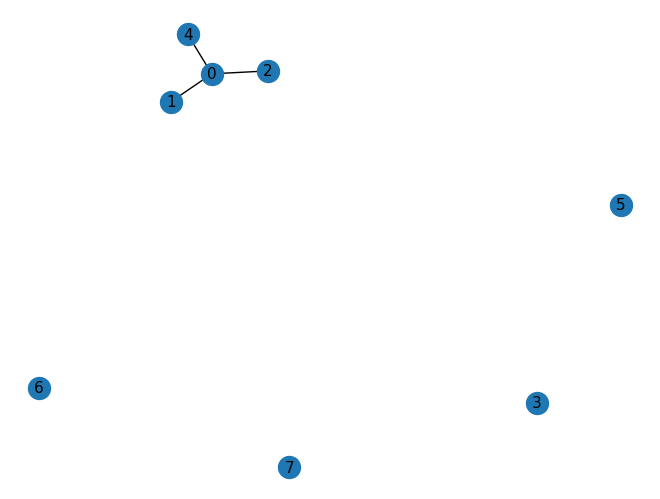

In [5]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

In [29]:
state = basisStates(L=4) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [30]:
print(H)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16 stored elements and shape (16, 16)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 4)	1.0
  (0, 8)	1.0
  (1, 0)	1.0
  (1, 5)	1.0
  (2, 0)	1.0
  (2, 10)	1.0
  (4, 0)	1.0
  (4, 5)	1.0
  (5, 1)	1.0
  (5, 4)	1.0
  (8, 0)	1.0
  (8, 10)	1.0
  (10, 2)	1.0
  (10, 8)	1.0


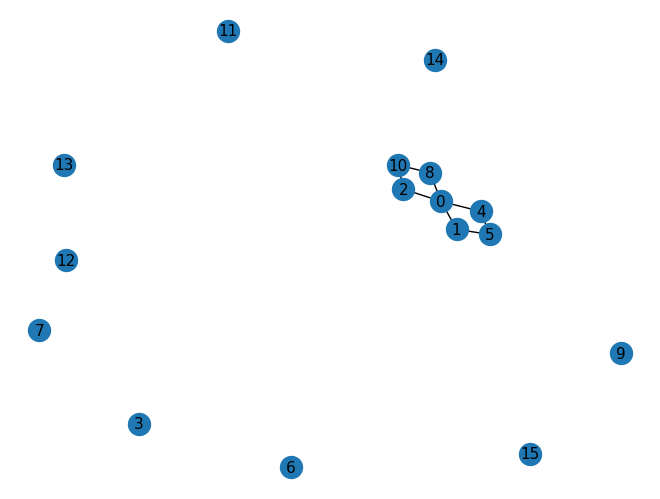

In [8]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

In [9]:
blocks = list(nx.connected_components(G)) # looking at all the blocks when L = 4

biggest_block = max(blocks, key=len) # Taking the biggest block

print(blocks)
print(biggest_block)

H_biggest_block = H[list(biggest_block), :][:, list(biggest_block)]

print(H_biggest_block)

[{0, 1, 2, 4, 5, 8, 10}, {3}, {6}, {7}, {9}, {11}, {12}, {13}, {14}, {15}]
{0, 1, 2, 4, 5, 8, 10}
<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 16 stored elements and shape (7, 7)>
  Coords	Values
  (0, 1)	1.0
  (0, 2)	1.0
  (0, 3)	1.0
  (0, 5)	1.0
  (1, 0)	1.0
  (1, 4)	1.0
  (2, 0)	1.0
  (2, 6)	1.0
  (3, 0)	1.0
  (3, 4)	1.0
  (4, 1)	1.0
  (4, 3)	1.0
  (5, 0)	1.0
  (5, 6)	1.0
  (6, 2)	1.0
  (6, 5)	1.0


In [10]:
H_biggest_block.toarray()

array([[0., 1., 1., 1., 0., 1., 0.],
       [1., 0., 0., 0., 1., 0., 0.],
       [1., 0., 0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 1., 0., 0.],
       [0., 1., 0., 1., 0., 0., 0.],
       [1., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 1., 0.]])

In [11]:
state = basisStates(L=5) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

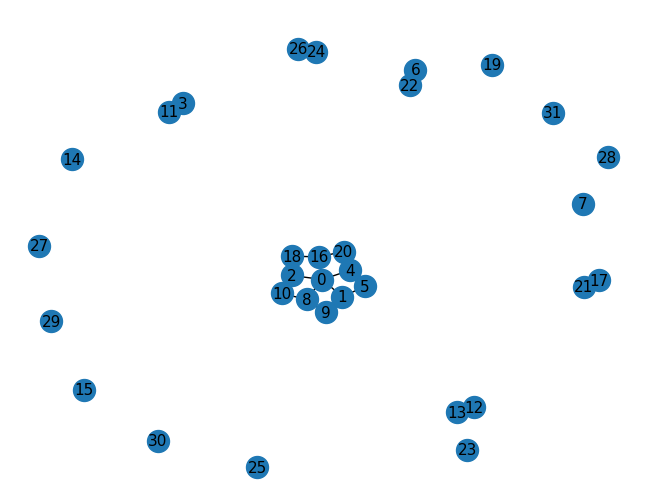

In [12]:
G = nx.from_scipy_sparse_array(H)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=250, font_size=11)

plt.show()

### Task 2

- Create a dense matrix version of the biggest block of the Hamiltonian and fully diagonalize it. 
- Later use as reference for benchmarking the polynomial filtering code.

In [13]:
state = basisStates(L=16) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

In [14]:
G = nx.from_scipy_sparse_array(H)

blocks = list(nx.connected_components(G)) # looking at all the blocks when L = 4

biggest_block = max(blocks, key=len) # Taking the biggest block

H_biggest_block = H[list(biggest_block), :][:, list(biggest_block)]

In [15]:
eigenvalues, eigenvectors = la.eigh(H_biggest_block.toarray())

In [16]:
eigenvalues

array([-9.6569893 , -8.68876573, -8.48619095, ...,  8.48619095,
        8.68876573,  9.6569893 ], shape=(2207,))

In [17]:
eigenvectors

array([[-1.22789012e-01, -1.06306208e-16, -1.57618855e-18, ...,
        -7.71200641e-17, -1.41117797e-17,  1.22789012e-01],
       [ 7.41107611e-02, -3.57656335e-02,  1.86738860e-02, ...,
        -4.14544929e-02,  3.57656335e-02,  7.41107611e-02],
       [ 7.41107611e-02,  3.57656335e-02, -3.70923063e-02, ...,
         5.21922723e-02, -3.57656335e-02,  7.41107611e-02],
       ...,
       [ 6.93218659e-03, -2.83240194e-03, -1.07569780e-03, ...,
        -1.01462648e-02,  2.83240194e-03,  6.93218659e-03],
       [ 6.96408978e-03, -8.55974707e-03,  8.27116189e-03, ...,
         1.28405625e-03,  8.55974707e-03,  6.96408978e-03],
       [ 9.85803648e-03,  4.20620917e-03, -3.12252592e-03, ...,
         7.89031395e-03, -4.20620917e-03,  9.85803648e-03]],
      shape=(2207, 2207))

In [18]:
np.save("eigenvalues_L16.npy", eigenvalues)
np.save("eigenvectors_L16.npy", eigenvectors)

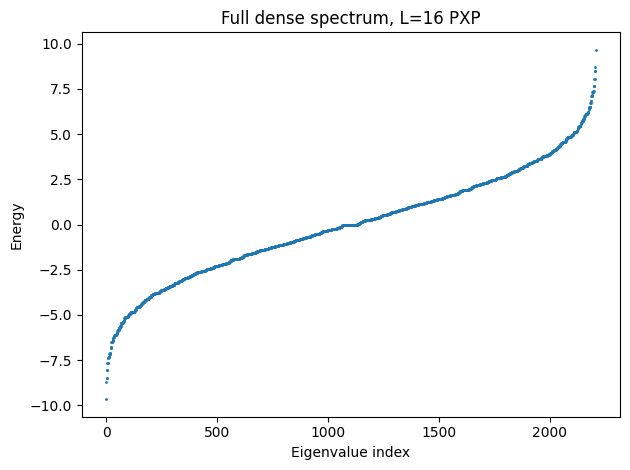

In [19]:
plt.figure()
plt.plot(eigenvalues, ".", markersize=2)
plt.xlabel("Eigenvalue index")
plt.ylabel("Energy")
plt.title("Full dense spectrum, L=16 PXP")
plt.tight_layout()
plt.show()

### Task 3

- The model is translation invariant. Create a basis of symmetrized momentum states (using only the restricted basis of the biggest block) to block diagonalize the biggest block in momentum sectors with moment k. 

- Check that you recover all eigenvalues obtained in Task 2.

In [ ]:
state = basisStates(L = 5)

representatives = []

for j in range(state.dim):
    translations = []
    for i in range(state.L):
        translated_state_index = state.translate(j, shift = i)
        translations.append(translated_state_index)
    translations.sort()

    if translations[0] not in representatives:
        representatives.append(translations[0]) # Take the representative as the smallest index in the list translations
    print(f"State index: {j}, Translations: {translations}")

print(f"Representatives: {representatives}")


State index: 0, Translations: [0, 0, 0, 0, 0]
State index: 1, Translations: [1, 2, 4, 8, 16]
State index: 2, Translations: [1, 2, 4, 8, 16]
State index: 3, Translations: [3, 6, 12, 17, 24]
State index: 4, Translations: [1, 2, 4, 8, 16]
State index: 5, Translations: [5, 9, 10, 18, 20]
State index: 6, Translations: [3, 6, 12, 17, 24]
State index: 7, Translations: [7, 14, 19, 25, 28]
State index: 8, Translations: [1, 2, 4, 8, 16]
State index: 9, Translations: [5, 9, 10, 18, 20]
State index: 10, Translations: [5, 9, 10, 18, 20]
State index: 11, Translations: [11, 13, 21, 22, 26]
State index: 12, Translations: [3, 6, 12, 17, 24]
State index: 13, Translations: [11, 13, 21, 22, 26]
State index: 14, Translations: [7, 14, 19, 25, 28]
State index: 15, Translations: [15, 23, 27, 29, 30]
State index: 16, Translations: [1, 2, 4, 8, 16]
State index: 17, Translations: [3, 6, 12, 17, 24]
State index: 18, Translations: [5, 9, 10, 18, 20]
State index: 19, Translations: [7, 14, 19, 25, 28]
State index: 2

In [5]:
state = basisStates(L=5) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for k in range(state.L):
        j = state.translate(i, shift=k)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

T_matrix = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))
print(T_matrix)

T_matrix_dense = T_matrix.toarray()
print(T_matrix_dense)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 152 stored elements and shape (32, 32)>
  Coords	Values
  (0, 0)	5.0
  (1, 1)	1.0
  (1, 2)	1.0
  (1, 4)	1.0
  (1, 8)	1.0
  (1, 16)	1.0
  (2, 1)	1.0
  (2, 2)	1.0
  (2, 4)	1.0
  (2, 8)	1.0
  (2, 16)	1.0
  (3, 3)	1.0
  (3, 6)	1.0
  (3, 12)	1.0
  (3, 17)	1.0
  (3, 24)	1.0
  (4, 1)	1.0
  (4, 2)	1.0
  (4, 4)	1.0
  (4, 8)	1.0
  (4, 16)	1.0
  (5, 5)	1.0
  (5, 9)	1.0
  (5, 10)	1.0
  (5, 18)	1.0
  :	:
  (26, 13)	1.0
  (26, 21)	1.0
  (26, 22)	1.0
  (26, 26)	1.0
  (27, 15)	1.0
  (27, 23)	1.0
  (27, 27)	1.0
  (27, 29)	1.0
  (27, 30)	1.0
  (28, 7)	1.0
  (28, 14)	1.0
  (28, 19)	1.0
  (28, 25)	1.0
  (28, 28)	1.0
  (29, 15)	1.0
  (29, 23)	1.0
  (29, 27)	1.0
  (29, 29)	1.0
  (29, 30)	1.0
  (30, 15)	1.0
  (30, 23)	1.0
  (30, 27)	1.0
  (30, 29)	1.0
  (30, 30)	1.0
  (31, 31)	5.0
[[5. 0. 0. ... 0. 0. 0.]
 [0. 1. 1. ... 0. 0. 0.]
 [0. 1. 1. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 1. 1. 0.]
 [0. 0. 0. ... 1. 1. 0.]
 [0. 0. 0. ... 0. 0. 5.]]


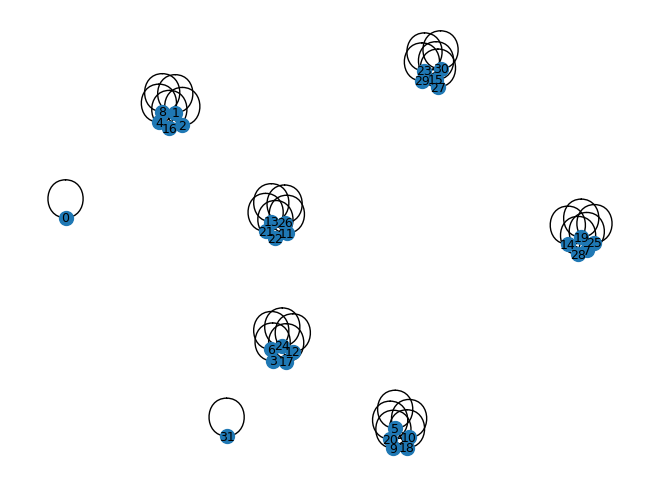

In [10]:
G = nx.from_scipy_sparse_array(T_matrix)

positions = nx.spring_layout(G)

nx.draw(G, positions, with_labels=True, node_size=100, font_size=9)

plt.show()

In [3]:
state = basisStates(L = 5)

representatives = []

for j in range(state.dim):
    translations = []
    for i in range(state.L):
        translated_state_index = state.translate(j, shift = i)
        translations.append(translated_state_index)
    translations.sort()

    if translations[0] not in representatives:
        representatives.append(translations[0]) # Take the representative as the smallest index in the list translations


all_orbits = []

for representative in representatives:
    orbit = []
    temporary_representative = representative
    for i in range(state.L):
        if temporary_representative not in orbit:
            orbit.append(temporary_representative)
            temporary_representative = state.translate(temporary_representative, shift=1)
    all_orbits.append(orbit)

print(f"All orbits: {all_orbits} + \n")

allowed_orbits = {}

for n_k in range(state.L):
    allowed_orbits[n_k] = []
    for orbit in all_orbits:
        f_n = len(orbit)

        if f_n * n_k % state.L == 0:
            allowed_orbits[n_k].append(orbit)

for n_k in allowed_orbits:
    print(f"n_k: {n_k}, Allowed orbits: {allowed_orbits[n_k]}")

All orbits: [[0], [1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30], [31]] + 

n_k: 0, Allowed orbits: [[0], [1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30], [31]]
n_k: 1, Allowed orbits: [[1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30]]
n_k: 2, Allowed orbits: [[1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30]]
n_k: 3, Allowed orbits: [[1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30]]
n_k: 4, Allowed orbits: [[1, 16, 8, 4, 2], [3, 17, 24, 12, 6], [5, 18, 9, 20, 10], [7, 19, 25, 28, 14], [11, 21, 26, 13, 22], [15, 23, 27, 29, 30]]


In [4]:
orbit = [1, 16, 8, 4, 2]

for r, index in enumerate(orbit):
    print(r, index)

0 1
1 16
2 8
3 4
4 2


In [ ]:
momentum_states = {}

for n_k in allowed_orbits:
    momentum_states[n_k] = []
    for orbit in allowed_orbits[n_k]:
        f_n = len(orbit)
        k = 2 * np.pi * n_k / state.L
        momentum_state = np.zeros(state.dim, dtype = complex)
        for r, index in enumerate(orbit): # we want the correct phases
            momentum_state[index] += np.exp(-1j * k * r) / np.sqrt(f_n)

        momentum_states[n_k].append(momentum_state)

In [5]:
# Implementing the above method to the biggest block

# Constructing the biggest block

state = basisStates(L=16) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

# Implementing the method

G = nx.from_scipy_sparse_array(H)

blocks = list(nx.connected_components(G)) # looking at all the blocks

biggest_block = max(blocks, key=len) # Taking the biggest block

biggest_block = sorted(biggest_block) # Sorting it so we have a nicer view

H_biggest_block = H[biggest_block, :][:, biggest_block]

representatives_biggest_block = []

for j in biggest_block:
    translations = []
    for i in range(state.L):
        new_index = state.translate(j, shift=i)
        if new_index in biggest_block: # We only want the states that are in the biggest block 
            translations.append(new_index)
    translations.sort()
    if translations[0] not in representatives_biggest_block:
        representatives_biggest_block.append(translations[0])


all_orbits_biggest_block = []

for representative in representatives_biggest_block:
    orbit = []
    temporary_representative = representative
    for i in range(state.L):
        if temporary_representative in biggest_block: # We only want the states that are in the biggest block 
            if temporary_representative not in orbit:
                orbit.append(temporary_representative)
        temporary_representative = state.translate(temporary_representative, shift=1)
    all_orbits_biggest_block.append(orbit)


allowed_orbits_biggest_block = {}

for n_k in range(state.L):
    allowed_orbits_biggest_block[n_k] = []
    for orbit in all_orbits_biggest_block:
        f_n = len(orbit)
        if f_n * n_k % state.L == 0:
            allowed_orbits_biggest_block[n_k].append(orbit)

biggest_block_indices_vs_original_indices = {}

for biggest_block_index in range(len(biggest_block)): # We reindex the biggest block basis states
    original_index = biggest_block[biggest_block_index]
    biggest_block_indices_vs_original_indices[original_index] = biggest_block_index 

momentum_states_biggest_block = {}

for n_k in allowed_orbits_biggest_block:
    momentum_states_biggest_block[n_k] = []
    for orbit in allowed_orbits_biggest_block[n_k]:
        f_n = len(orbit)
        k = 2 * np.pi * n_k / state.L
        momentum_state = np.zeros(len(biggest_block), dtype=complex)
        for r, index in enumerate(orbit):
            biggest_block_index = biggest_block_indices_vs_original_indices[index]
            momentum_state[biggest_block_index] += np.exp(-1j * k * r) / np.sqrt(f_n)
        momentum_states_biggest_block[n_k].append(momentum_state)

# Finding the eigenvalues

H_biggest_block_momentum = {}
biggest_block_eigvals = {}

for n_k in momentum_states_biggest_block:

    V = np.column_stack(momentum_states_biggest_block[n_k])

    HV = H_biggest_block.dot(V)

    H_k = np.matmul(V.conj().T, HV)

    eigenvalues, eigenvectors = np.linalg.eigh(H_k)

    H_biggest_block_momentum[n_k] = H_k
    biggest_block_eigvals[n_k] = eigenvalues

In [4]:
# checking the eigenvalues with task 2

eigvals_list_task3 = []

for n_k in biggest_block_eigvals:
    for value in biggest_block_eigvals[n_k]:
        eigvals_list_task3.append(value)

eigvals_list_task3 = np.sort(np.array(eigvals_list_task3))
eigvals_list_task2 = np.sort(np.load("eigenvalues_L16.npy"))

max_difference = np.max(np.abs(eigvals_list_task2 - eigvals_list_task3))

tolerance = 10 ** -12

if max_difference < tolerance:
    print(True)
else:
    print(False)

True


### Task 4

- Calculate all eigenvectors the $k = 0$ block. 
- For each eigenvector, create a representation of the vector in the full basis. in binary counting order. 
- Use this representation to calculate the entropy of entanglement across a cut in the middle of the system by simple reshaping and calculating a singular value decomposition (SVD) of the resulting matrix. (Ulrich Schollwöck’s lecture notes arXiv:1008.3477 leading up to Eq. (25) for the exact procedure.)
- Calculate the entanglement entropy of every eigenvector and plot them against the corresponding eigenvalue. 

In the end a structure similar to Fig. (3a) in Phys. Rev. B 98, 155134
(2018) should be seen. Quantum many-body scar states are identified by an atypically low entanglement entropy in the middle of the spectrum.


In [6]:
# eigenvectors of the k = 0 block

n_k = 0

V = np.column_stack(momentum_states_biggest_block[n_k])

HV = H_biggest_block.dot(V)

H_0 = np.matmul(V.conj().T, HV)

eigenvalues_0, eigenvectors_0 = np.linalg.eigh(H_0)

eigenvectors_0_biggest_block_basis = np.matmul(V, eigenvectors_0) # psi_0 = V * x_0

In [7]:
eigenvectors_0_biggest_block_basis.shape # if the row > column then columns have the eigenvectors and vice versa

(2207, 143)

In [8]:
# full basis representation

eigenvectors_0_full_basis = np.zeros((state.dim, eigenvectors_0_biggest_block_basis.shape[1]), dtype=complex)
print("shape of the eigenvector matrix is:", eigenvectors_0_full_basis.shape)

for i, original_index in enumerate(biggest_block):
    eigenvectors_0_full_basis[original_index, :] = eigenvectors_0_biggest_block_basis[i, :]

# we basically take all values at the biggest block basis eigenvector matrix and put them in their respective places in the full basis matrix

shape of the eigenvector matrix is: (65536, 143)


In [9]:
# entanglement entropy for every state in the eigenvector matrix by reshaping by a cut in the middle

entropies = []

for a in range(eigenvectors_0_full_basis.shape[1]):
    eigenstate = eigenvectors_0_full_basis[:, a]

    reshaped_eigenstate = eigenstate.reshape((2**(state.L // 2), 2**(state.L // 2)))

    U, s, Vdagger = np.linalg.svd(reshaped_eigenstate, full_matrices=False)
    
    entropy = 0

    for schmidt_value in s:
        if schmidt_value > 1e-15:
            entropy+= -(schmidt_value**2 * np.log(schmidt_value**2))
    
    entropies.append(entropy)


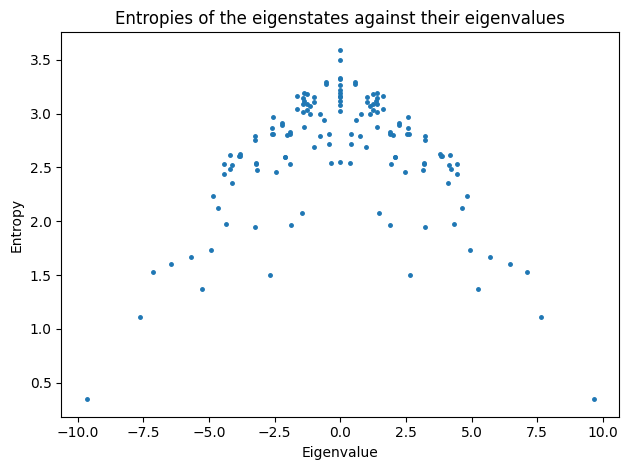

In [10]:
plt.figure()
plt.plot(eigenvalues_0, entropies, ".", markersize = 5)
plt.xlabel("Eigenvalue")
plt.ylabel("Entropy")
plt.title("Entropies of the eigenstates against their eigenvalues")
plt.tight_layout()
plt.show()

### Task 5

- Using a sparse matrix representation of the $k = 0$ block $H_{k=0}$, write a function to apply a Chebyshev polynomial of this block to a vector, i.e. to calculate $x' = p(H_{k=0})x$. 

- Plug this function into scipy.sparse.linalg.eigsh (use the LinearOperator interface) to calculate exact eigenvectors of $H_{k=0}$ in the middle of the spectrum. 

- Try to find scar states with this procedure by choosing a polynomial which targets a specific eigenvalue (cf. script, essentially expand the delta function at the target value in terms of Chebyshev polynomials). 

- Calculate several (e.g. 20) eigenpairs close to a target and calculate and plot the entanglement entropy of each eigenvector. 

- Report the highest system sizes reached.

In [3]:
from scipy.sparse.linalg import LinearOperator, aslinearoperator
from scipy.sparse.linalg import eigsh

In [13]:
# Sparse H0

H0_sparse = csr_matrix(H_biggest_block_momentum[0])

In [14]:
# Sparse H0 as linear operator

H0_operator = aslinearoperator(H0_sparse)

In [15]:
# Applying 3.29 from Lecture Notes

lambda_max = np.max(eigenvalues_0)

def p(k, operator, vec_x):
    c = []
    for m in range(k + 1):
        if m == 0:
            c.append(1)
        else:
            c.append(2 * np.cos(m * np.pi / 2))

    T0 = vec_x.copy() # starts as c_0 * identity * vec_x
    polynomial = c[0] * vec_x.copy()

    T1 = vec_x + (operator.matvec(vec_x) - lambda_max * vec_x) / lambda_max
    polynomial = polynomial + c[1] * T1

    for i in range(1, k):
        T2 = 2.0 * (T1 + (operator.matvec(T1) - lambda_max * T1) / lambda_max) - T0
        polynomial = polynomial + c[i + 1] * T2

        T0 = T1
        T1 = T2

    return polynomial

In [16]:
H0_operator.shape

(143, 143)

In [17]:
N = H0_operator.shape[0]
order = 20

def matvec_p(v): # LinearOperator wants to have a matrix times vector method so we need to define a new function from p 
    return p(order, H0_operator, v)

p_operator = LinearOperator((N, N), matvec = matvec_p, dtype=complex)

In [18]:
chebyshev_eigenvalues, chebyshev_eigenvectors = eigsh(p_operator, k=20, which="LM")

In [19]:
actual_eigenvalues = []

for a in range(chebyshev_eigenvectors.shape[1]):
    eigenstate = chebyshev_eigenvectors[:, a]
    actual_eigenvalues.append(np.vdot(eigenstate, H0_operator.matvec(eigenstate)).real)

In [20]:
cheb_eigvec_biggest_block_basis = np.matmul(V, chebyshev_eigenvectors) 

cheb_eigvec_full_basis = np.zeros((state.dim, cheb_eigvec_biggest_block_basis.shape[1]), dtype=complex)
print("shape of the eigenvector matrix is:", cheb_eigvec_full_basis.shape)

for i, original_index in enumerate(biggest_block):
    cheb_eigvec_full_basis[original_index, :] = cheb_eigvec_biggest_block_basis[i, :]

shape of the eigenvector matrix is: (65536, 20)


In [21]:
entropies = []

for a in range(cheb_eigvec_full_basis.shape[1]):
    eigenstate = cheb_eigvec_full_basis[:, a]

    reshaped_eigenstate = eigenstate.reshape((2**(state.L // 2), 2**(state.L // 2)))

    U, s, Vdagger = np.linalg.svd(reshaped_eigenstate, full_matrices=False)
    
    entropy = 0

    for schmidt_value in s:
        if schmidt_value > 1e-15:
            entropy+= -(schmidt_value**2 * np.log(schmidt_value**2))
    
    entropies.append(entropy)

In [22]:
actual_eigenvalues = np.array(actual_eigenvalues)
entropies = np.array(entropies)

idx = np.argsort(actual_eigenvalues)

actual_eigenvalues = actual_eigenvalues[idx]
entropies = entropies[idx]

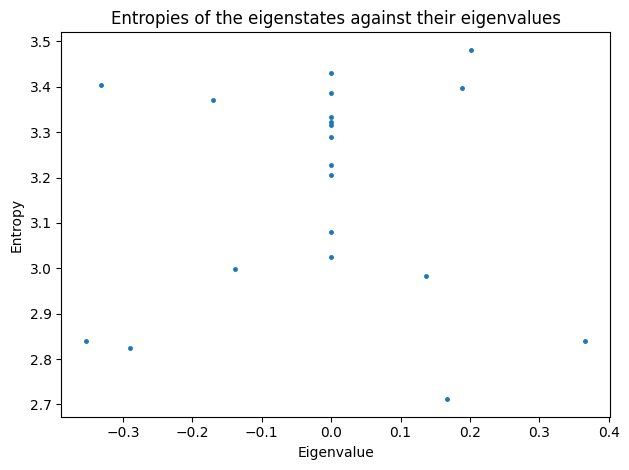

In [23]:
plt.figure()
plt.plot(actual_eigenvalues, entropies, ".", markersize = 5)
plt.xlabel("Eigenvalue")
plt.ylabel("Entropy")
plt.title("Entropies of the eigenstates against their eigenvalues")
plt.tight_layout()
plt.show()

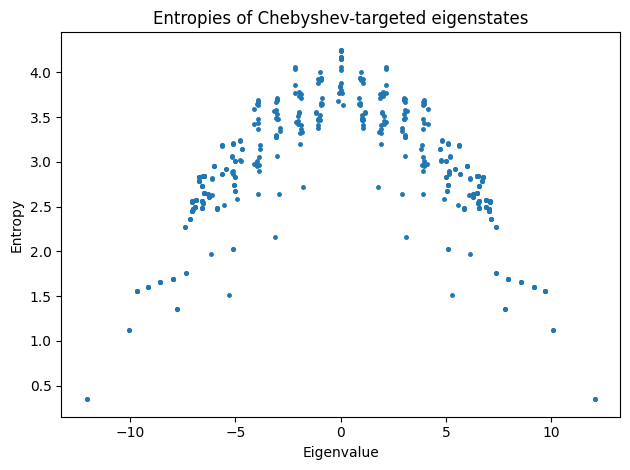

In [4]:
# Scaling up, we need to get rid of the dense part

state = basisStates(L=20) 

rows = []
cols = []
data = []

for i in range(state.dim):
    for site in range(state.L):
        j = state.pxp(i, site)

        if j is not None:
            rows.append(j)
            cols.append(i)
            data.append(1.0)

H = csr_matrix((data, (rows, cols)), shape=(state.dim, state.dim))

# Implementing the method

G = nx.from_scipy_sparse_array(H)

blocks = list(nx.connected_components(G)) # looking at all the blocks

biggest_block = max(blocks, key=len) # Taking the biggest block

biggest_block = sorted(biggest_block) # Sorting it so we have a nicer view

H_biggest_block = H[biggest_block, :][:, biggest_block]


representatives_biggest_block = []

for j in biggest_block:
    translations = []
    for i in range(state.L):
        new_index = state.translate(j, shift=i)
        if new_index in biggest_block: # We only want the states that are in the biggest block 
            translations.append(new_index)
    translations.sort()
    if translations[0] not in representatives_biggest_block:
        representatives_biggest_block.append(translations[0])


all_orbits_biggest_block = []

for representative in representatives_biggest_block:
    orbit = []
    temporary_representative = representative
    for i in range(state.L):
        if temporary_representative in biggest_block: # We only want the states that are in the biggest block 
            if temporary_representative not in orbit:
                orbit.append(temporary_representative)
        temporary_representative = state.translate(temporary_representative, shift=1)
    all_orbits_biggest_block.append(orbit)


# for k=0, every orbit is allowed, so we do not need to find allowed orbits

biggest_block_indices_vs_original_indices = {}

for biggest_block_index in range(len(biggest_block)): # We reindex the biggest block basis states
    original_index = biggest_block[biggest_block_index]
    biggest_block_indices_vs_original_indices[original_index] = biggest_block_index 

# also building the basis change matrix V sparsely

rows_V = []
cols_V = []
data_V = []

for orbit_number, orbit in enumerate(all_orbits_biggest_block):
    f_n = len(orbit)

    for index in orbit:
        biggest_block_index = biggest_block_indices_vs_original_indices[index]

        rows_V.append(biggest_block_index)
        cols_V.append(orbit_number)
        data_V.append(1.0 / np.sqrt(f_n))

V0_sparse = csr_matrix((data_V, (rows_V, cols_V)), shape=(len(biggest_block), len(all_orbits_biggest_block)), dtype=complex)


H0_sparse = V0_sparse.conj().T.dot(H_biggest_block).dot(V0_sparse)
H0_operator = aslinearoperator(H0_sparse)


lambda_max = np.max(np.abs(eigsh(H0_sparse, k=1, which="LA", return_eigenvectors=False)[0]))


# Applying Chebyshev filter from lecture notes, with a target eigenvalue

def p_target(k, operator, vec_x, target, lambda_max):
    x_target = target / lambda_max

    c = []

    for m in range(k + 1):
        if m == 0:
            c.append(1.0)
        else:
            c.append(2.0 * np.cos(m * np.arccos(x_target)))

    T0 = vec_x.copy() # starts as c_0 * identity * vec_x
    polynomial = c[0] * T0

    T1 = vec_x + (operator.matvec(vec_x) - lambda_max * vec_x) / lambda_max
    polynomial = polynomial + c[1] * T1

    for i in range(1, k):
        T2 = 2.0 * (T1 + (operator.matvec(T1) - lambda_max * T1) / lambda_max) - T0
        polynomial = polynomial + c[i + 1] * T2

        T0 = T1
        T1 = T2

    return polynomial


targets = np.linspace(-state.L-1, state.L+1, 2*(state.L+1)+1)

order = 20
N = H0_operator.shape[0]

all_actual_eigenvalues = []
all_entropies = []

for target in targets:
    if abs(target) >= lambda_max:
        continue
    
    def matvec_p_target(v, target=target):
        return p_target(order, H0_operator, v, target, lambda_max)
    
    p_target_operator = LinearOperator((N, N), matvec=matvec_p_target, dtype=complex)
    chebyshev_eigenvalues, chebyshev_eigenvectors = eigsh(p_target_operator, k=20, which="LM")
    cheb_eigvec_biggest_block_basis = V0_sparse.dot(chebyshev_eigenvectors)
    cheb_eigvec_full_basis = np.zeros((state.dim, cheb_eigvec_biggest_block_basis.shape[1]), dtype=complex)
    
    for i, original_index in enumerate(biggest_block):
        cheb_eigvec_full_basis[original_index, :] = cheb_eigvec_biggest_block_basis[i, :]
    
    entropies = []
    actual_eigenvalues = []
    
    for a in range(cheb_eigvec_full_basis.shape[1]):
        eigenstate_k0 = chebyshev_eigenvectors[:, a]
        actual_energy = np.vdot(eigenstate_k0, H0_operator.matvec(eigenstate_k0)).real
        eigenstate = cheb_eigvec_full_basis[:, a]
        reshaped_eigenstate = eigenstate.reshape((2**(state.L // 2), 2**(state.L // 2)))
        U, s, Vdagger = np.linalg.svd(reshaped_eigenstate, full_matrices=False)
        entropy = 0
    
        for schmidt_value in s:
            if schmidt_value > 1e-15:
                entropy += -(schmidt_value**2 * np.log(schmidt_value**2))
    
        actual_eigenvalues.append(actual_energy)
        entropies.append(entropy)
    
    all_actual_eigenvalues.extend(actual_eigenvalues)
    all_entropies.extend(entropies)


all_actual_eigenvalues = np.array(all_actual_eigenvalues)
all_entropies = np.array(all_entropies)


plt.figure()
plt.plot(all_actual_eigenvalues, all_entropies, ".", markersize=5)
plt.xlabel("Eigenvalue")
plt.ylabel("Entropy")
plt.title("Entropies of Chebyshev-targeted eigenstates")
plt.tight_layout()
plt.show()